PCA-principal component analysis

import libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

create a dataset

In [5]:
data=pd.DataFrame({
    "Study_Hours":[2,4,5,7,8,10],
    "Attendance_Percent": [50,60,65,75,85,95],
    "Assignment_Score": [35,45,55,65,80,95],
    "Final_Marks":[38,48,56,68,82,94]
})
display(data)

,Study_Hours,Attendance_Percent,Assignment_Score,Final_Marks
0,2,50,35,38
1,4,60,45,48
2,5,65,55,56
3,7,75,65,68
4,8,85,80,82
5,10,95,95,94


In [6]:
features=data[["Study_Hours","Attendance_Percent","Assignment_Score","Final_Marks"]]
print(features.min())
print(features.max())

Study_Hours            2
Attendance_Percent    50
Assignment_Score      35
Final_Marks           38
dtype: int64
Study_Hours           10
Attendance_Percent    95
Assignment_Score      95
Final_Marks           94
dtype: int64


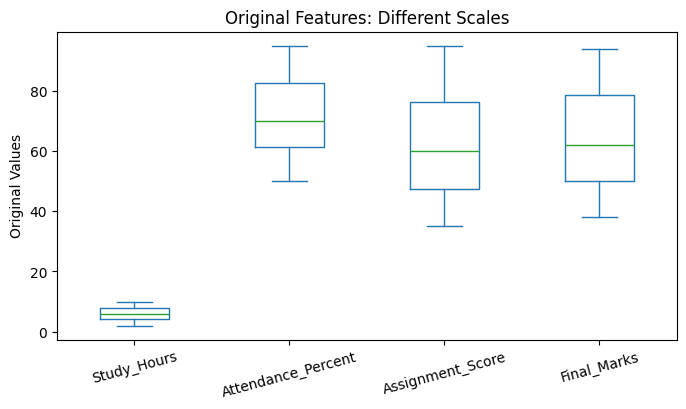

In [7]:
features.plot(kind="box",figsize=(8,4))
plt.title("Original Features: Different Scales")
plt.ylabel("Original Values")
plt.xticks(rotation=15)
plt.show()

normalisation

In [8]:
normalizer=MinMaxScaler()
normalized_array=normalizer.fit_transform(features)
normalized_df=pd.DataFrame(normalized_array,columns=features.columns,index=features.index)
display(normalized_df.round(3))

,Study_Hours,Attendance_Percent,Assignment_Score,Final_Marks
0,0.000,0.000,0.000,0.000
1,0.250,0.222,0.167,0.179
2,0.375,0.333,0.333,0.321
3,0.625,0.556,0.500,0.536
4,0.750,0.778,0.750,0.786
5,1.000,1.000,1.000,1.000


interpretation

In [9]:
print("Minimum after normalisation: ")
print(normalized_df.min())
print("Maximum after normalisation: ")
print(normalized_df.max())

Minimum after normalisation: 
Study_Hours           0.0
Attendance_Percent    0.0
Assignment_Score      0.0
Final_Marks           0.0
dtype: float64
Maximum after normalisation: 
Study_Hours           1.0
Attendance_Percent    1.0
Assignment_Score      1.0
Final_Marks           1.0
dtype: float64


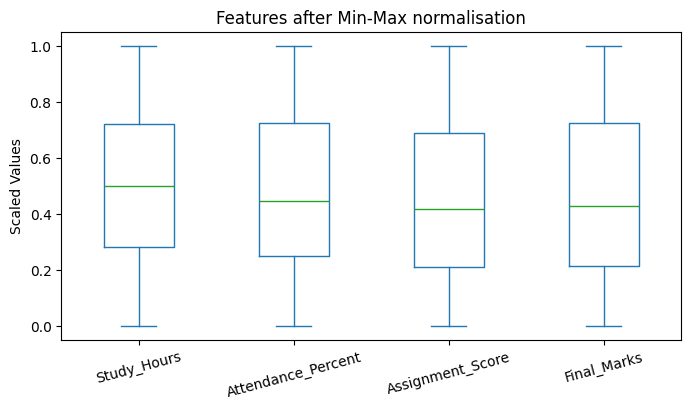

In [10]:
normalized_df.plot(kind="box",figsize=(8,4))
plt.title("Features after Min-Max normalisation")
plt.ylabel("Scaled Values")
plt.xticks(rotation=15)
plt.show()

standardisation-zscore

In [11]:
standardizer=StandardScaler()
standardized_array=standardizer.fit_transform(features)
standardized_df=pd.DataFrame(standardized_array,columns=features.columns,index=features.index)
display(standardized_df.round(3))

,Study_Hours,Attendance_Percent,Assignment_Score,Final_Marks
0,-1.512,-1.427,-1.351,-1.364
1,-0.756,-0.768,-0.859,-0.846
2,-0.378,-0.439,-0.368,-0.432
3,0.378,0.220,0.123,0.190
4,0.756,0.878,0.859,0.915
5,1.512,1.537,1.596,1.537


verify the result

In [13]:
print("Mean after standardisation: ")
print(standardized_df.mean().round(6))
print("Standard deviation after standardisation: ")
print(standardized_df.std(ddof=0).round(6))

Mean after standardisation: 
Study_Hours           0.0
Attendance_Percent   -0.0
Assignment_Score      0.0
Final_Marks           0.0
dtype: float64
Standard deviation after standardisation: 
Study_Hours           1.0
Attendance_Percent    1.0
Assignment_Score      1.0
Final_Marks           1.0
dtype: float64


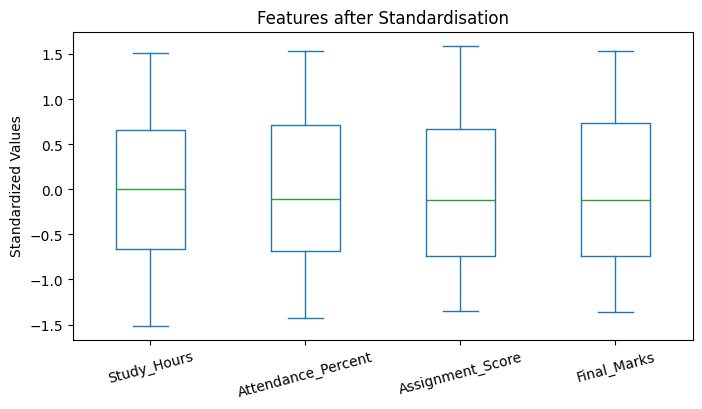

In [14]:
standardized_df.plot(kind="box",figsize=(8,4))
plt.title("Features after Standardisation")
plt.ylabel("Standardized Values")
plt.xticks(rotation=15)
plt.show()

PCA

In [18]:
scaled_features=StandardScaler().fit_transform(features)
pca=PCA(n_components=2)
pca_array=pca.fit_transform(scaled_features)
pca_df=pd.DataFrame(data=pca_array,columns=["PC1","PC2"])
index=features.index

display(pca_df.round(3))

,PC1,PC2
0,-2.827,-0.129
1,-1.615,0.079
2,-0.809,0.011
3,0.455,0.186
4,1.705,-0.100
5,3.091,-0.046


In [19]:
variance_ratios=pca.explained_variance_ratio_
for component, ratio in zip(["PC1","PC2"],variance_ratios):
  print(f"{component} explains {ratio: .2%} of the variance")
total_retained_variance=sum(variance_ratios)
print(f"Total variance retained: {total_retained_variance:.2%}")

PC1 explains  99.66% of the variance
PC2 explains  0.29% of the variance
Total variance retained: 99.95%


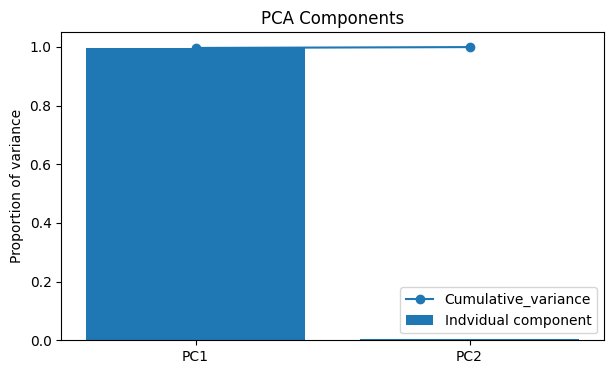

In [20]:
component_names=["PC1", "PC2"]
cumulative_variance=variance_ratios.cumsum()
plt.figure(figsize=(7,4))
plt.bar(component_names,variance_ratios)
plt.plot(component_names,cumulative_variance,marker="o")
plt.ylim(0,1.05)
plt.ylabel("Proportion of variance")
plt.title("PCA Components")
plt.legend(["Cumulative_variance","Indvidual component"])
plt.show()

In [21]:
print("Number of original input features: ",features.shape[1])
print("Number of PCA components: ",pca.n_components)
print("Original feature shape: ",features.shape)
print("Reduced PCA data shape:",pca_df.shape)

Number of original input features:  4
Number of PCA components:  2
Original feature shape:  (6, 4)
Reduced PCA data shape: (6, 2)
